# Лабораторная работа 2 Вариант 26
## Введение
**Название:** визуальный анализ данных

**Цель:** изучить программные средства, используемые для визуализации наборов данных

**Описание показателей:**
- age - возраст
- income - доход
- score - уровень вовлечённости
- height - рост
- weight - вес
- visits - количество посещений
- clicks - клики
- time_spent - время на платформе
- target - конверсия
## 1. Импортируем необходимые библиотеки

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
%matplotlib inline

## 2. Импортируем набор данных из файла user_behavior.csv и поместим его в объект DataFrame; выведем первые 10 строк

In [2]:
data = pd.read_csv("user_behavior.csv")
data.head(10)

,age,income,score,height,weight,visits,clicks,time_spent,target
0,39,59796,0.435,154.8,45.0,8,4,191,1
1,33,48031,0.709,164.3,63.9,5,4,366,0
2,41,45971,0.316,168.3,68.5,9,3,209,1
3,50,48756,0.508,189.0,94.7,9,5,314,0
4,32,35634,0.371,177.0,60.6,11,5,384,1
5,32,43243,0.366,160.0,67.1,8,4,240,0
6,50,73433,0.625,176.4,45.0,12,9,632,0
7,42,54317,0.500,158.1,50.5,8,5,306,0
8,30,48742,0.629,181.7,75.9,8,6,381,0
9,40,46265,0.357,167.8,75.4,12,6,287,0


## 3. Получим сводную информацию по датафрейму

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   age         1000 non-null   int64  
 1   income      1000 non-null   int64  
 2   score       1000 non-null   float64
 3   height      1000 non-null   float64
 4   weight      1000 non-null   float64
 5   visits      1000 non-null   int64  
 6   clicks      1000 non-null   int64  
 7   time_spent  1000 non-null   int64  
 8   target      1000 non-null   int64  
dtypes: float64(3), int64(6)
memory usage: 70.4 KB


## 4. Визуализация количественных признаков
### 4.1 Обычные гистограммы

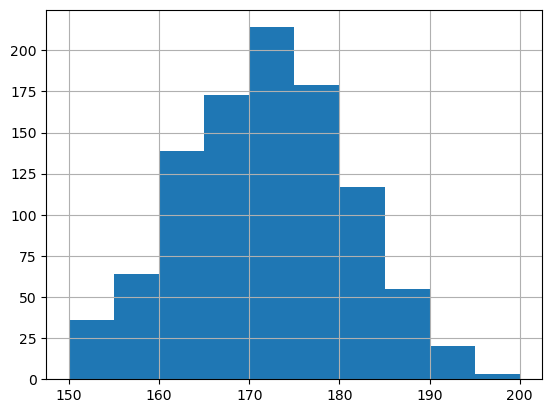

In [4]:
# выведем гистограмму роста людей
data['height'].hist();

Можем заметить, что большинство пользователей платформы имеет рост от 160 до 185. Попробуем вывести гистограммы всех численных показателей:

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'income'}>,
        <Axes: title={'center': 'score'}>],
       [<Axes: title={'center': 'height'}>,
        <Axes: title={'center': 'weight'}>,
        <Axes: title={'center': 'visits'}>],
       [<Axes: title={'center': 'clicks'}>,
        <Axes: title={'center': 'time_spent'}>,
        <Axes: title={'center': 'target'}>]], dtype=object)

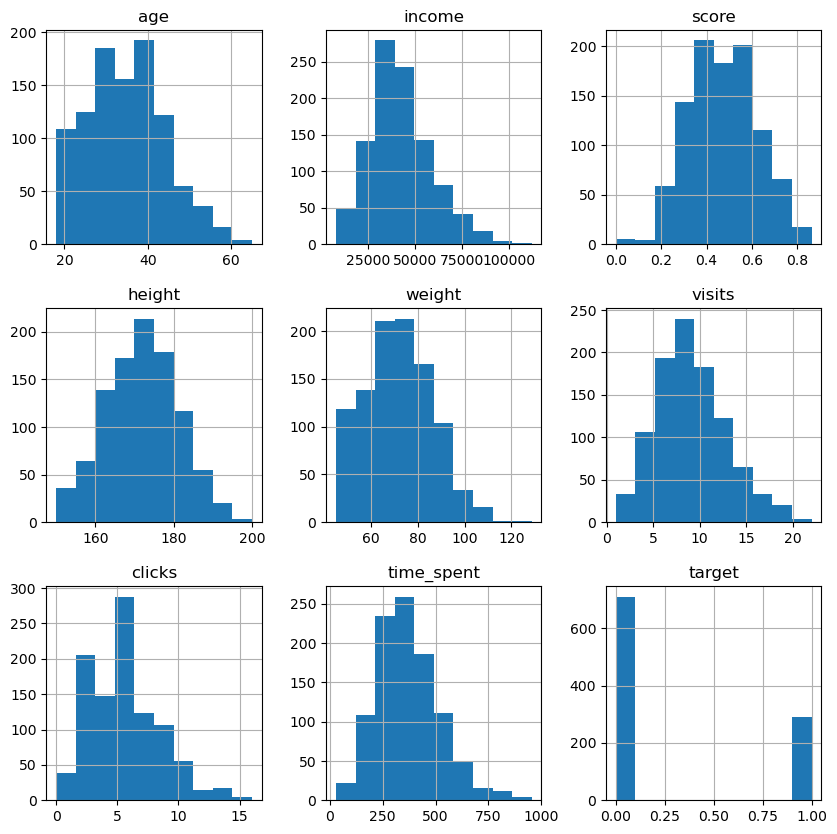

In [5]:
data.hist(figsize=(10,10))

По данным гистограмм можно сказать, что большинство пользователей платформы имеют возраст до 50 лет, проводят от 200 до 500 единиц времени, посещают сайт от 5 до 13 раз. 
### 4.2 Графики matplotlib
Выведем график с использованием matplotlib

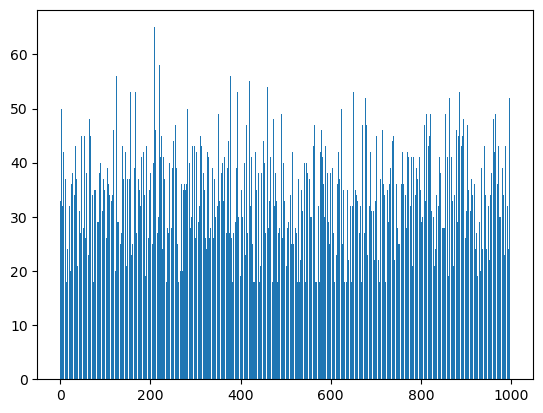

In [6]:
plt.bar(data.index, data['age'])
plt.show()

Данный график более удачно передаёт хронологию по индексам, но менее нагляден предыдущей гистограммы. Выведем график распределения:

<BarContainer object of 46 artists>

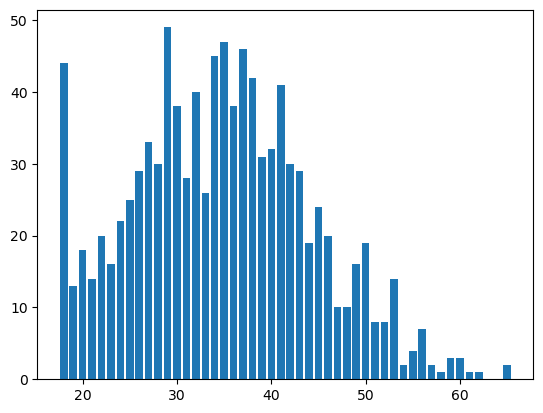

In [7]:
hist = data['age'].value_counts()
plt.bar(hist.index, hist)

Теперь график выглядит более наглядно, благодаря чему можно заметить: 
1. количество пользователей между 18 и 19, 20, 21 и т.д. лет сильно отличается;
2. если проанализировать целевую аудиторию платформы, то заметна возрастная группа примерно от 25 до 46 лет.

Можно предположить, что сайт доступен только пользователям от 18 лет, в следствие чего все молодые пользователи, имеющие значение возраста ниже, указывают при регистрации значение 18, что приводит к некорректному сбору даных для анализа (по сути значение 18 включает в себя диапозон возраста от 0 до 18).
### 4.3 Графики seaborn
Построим диаграмму типа "ящик с усами", позволяющую увидеть медиану, квадратили, интерквартильный размах и выбросы

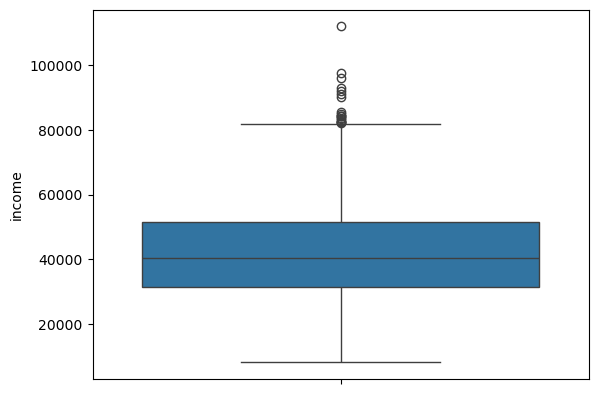

In [8]:
sns.boxplot(data['income']);

По данному графику видно, что медианное значение дохода 40000 условных единиц. При этом сам доход находится в примерно диапозоне от 5000 до 80000, с большинством в диапозоне от 30 до 55 тысяч. Также заметны выбросы выше верхней границы в 80000 условных единиц.
### 4.4 Сравнение признака по другому признаку (фильтры)
Попробуем сопоставить возраст и количество посещений

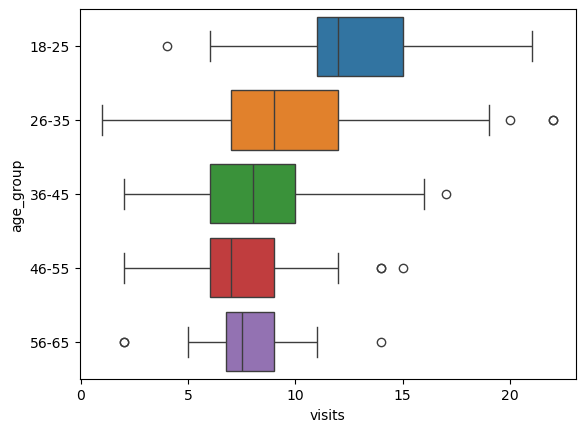

In [9]:
# создание категорий с помощью pd.cut
bins = [18, 26, 36, 46, 56, 66]
labels = ['18-25', '26-35', '36-45', '46-55', '56-65']
data['age_group'] = pd.cut(data['age'], bins=bins, labels=labels, right=False)

# подготовка графика
dataAGV = data[['age_group','visits']]
dataAGV = dataAGV.groupby('age_group', observed=False).sum()
dataAGV = dataAGV.sort_values('visits',ascending=False)
dataAGV = dataAGV[:5].index.values
sns.boxplot(y='age_group', x='visits', data=data[data.age_group.isin(dataAGV)], hue='age_group');

По результатам можно заметить, что чаще всего платформу посещают молодые люди.
## 5. Визуализация категориальных признаков
### 5.1 Столбчатые диаграммы
Построим график по категориальному признаку конверсии, принимающему только значения 0 или 1:

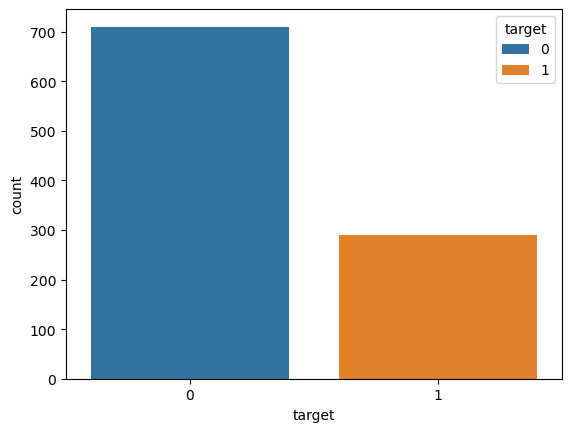

In [10]:
sns.countplot(data, x='target', hue='target')
plt.show()

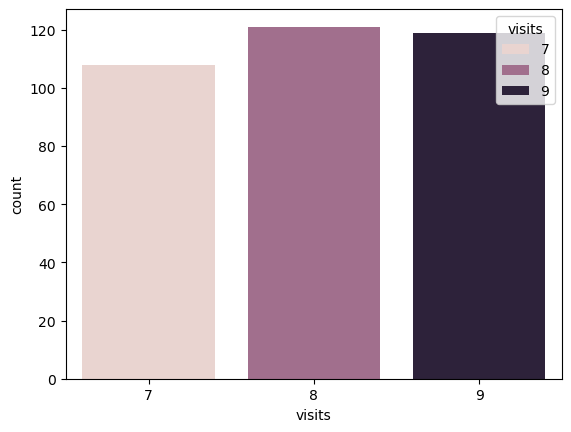

In [11]:
# выведем гистограмму трёх "популярных" количества визитов
sns.countplot(data[data['visits'].isin(data['visits'].value_counts().head(3).index)], x='visits', hue='visits')
plt.show()

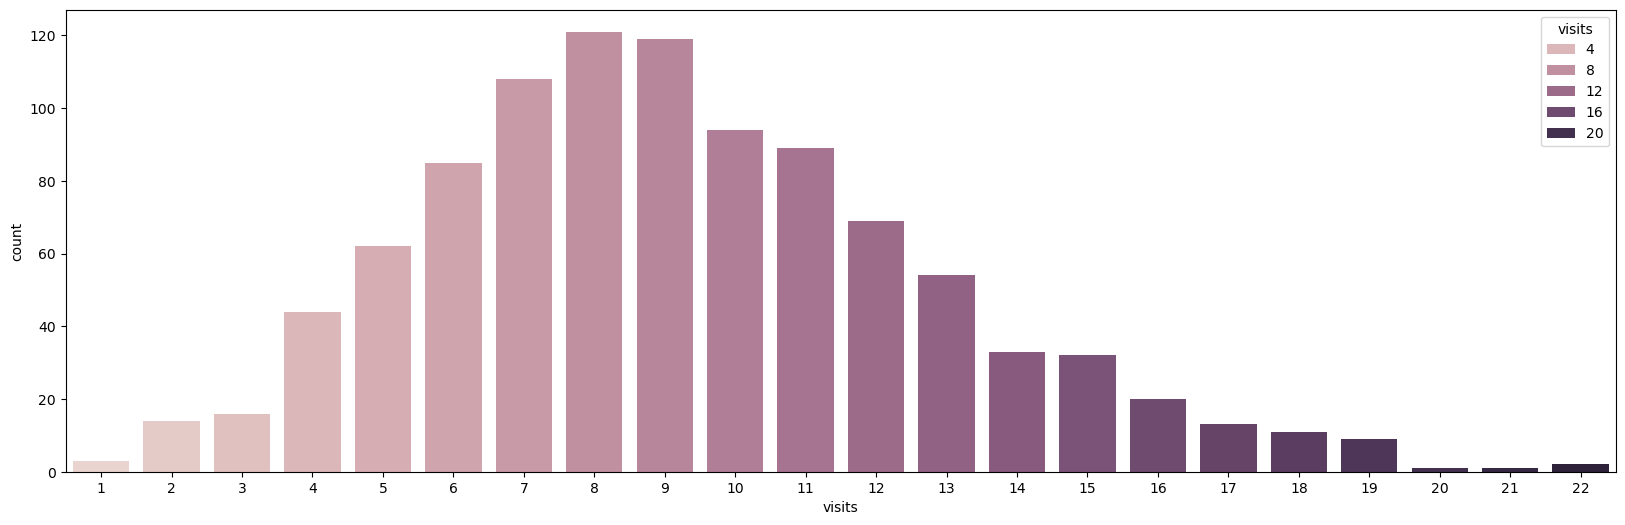

In [12]:
# гистограмма всех случаев посещения
fig = plt.subplots(figsize = (20,6))
sns.countplot(data, x='visits', hue='visits')
plt.show()

<BarContainer object of 10 artists>

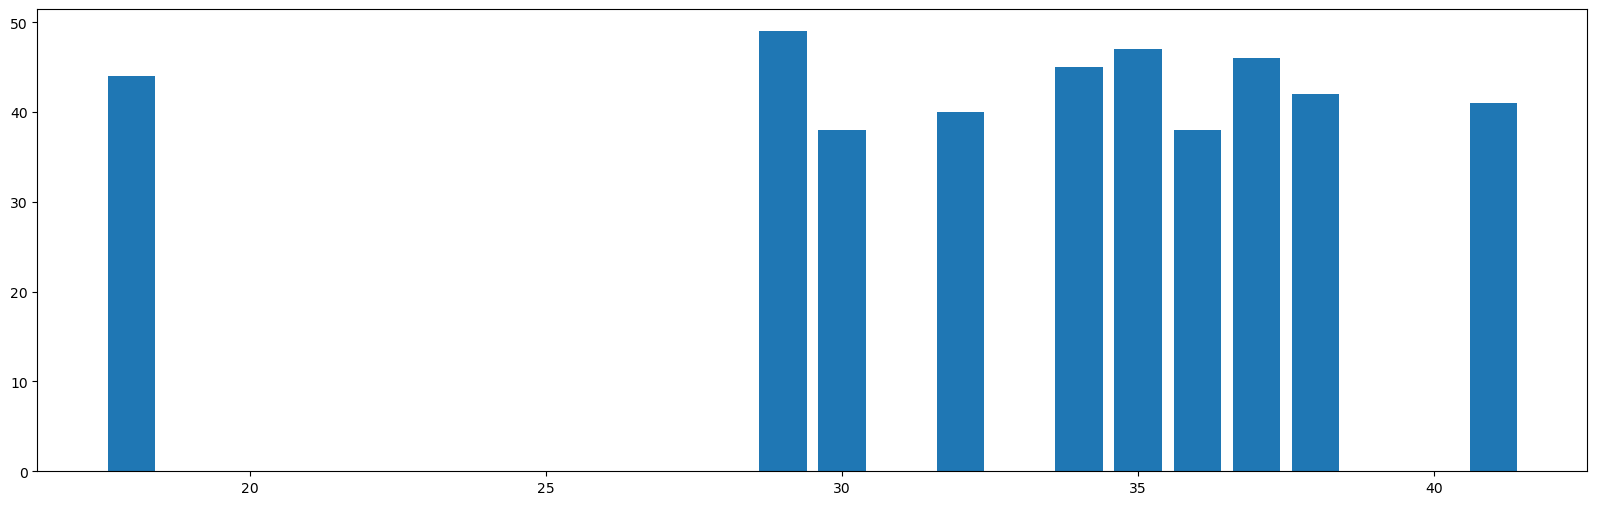

In [13]:
# определим 10 "популрных" возраста
fig = plt.subplots(figsize=(20, 6))
hist = data['age'].value_counts().head(10)
plt.bar(hist.index, hist)

### 5.2 Визуализация взаимосвязанных признаков

In [14]:
# список колонок
data.columns

Index(['age', 'income', 'score', 'height', 'weight', 'visits', 'clicks',
       'time_spent', 'target', 'age_group'],
      dtype='object')

In [15]:
# произведём отбор показателей, содержащих сочетание ei
eis = [s for s in data.columns if 'ei' in s]
eis

['height', 'weight']

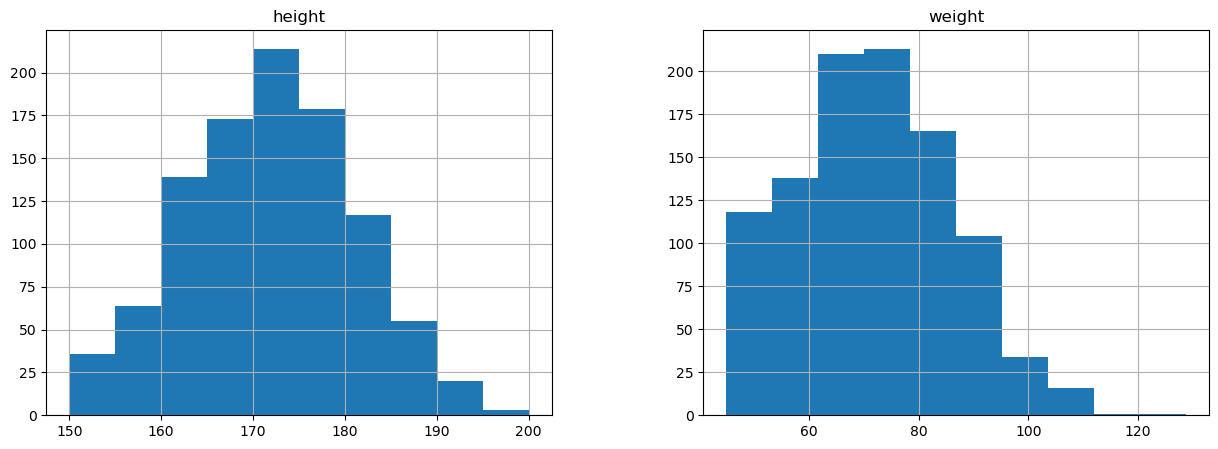

In [16]:
# построим отдельные гистограммы для нескольких признаков (рост и вес)
data[eis].hist(figsize=(15,5));

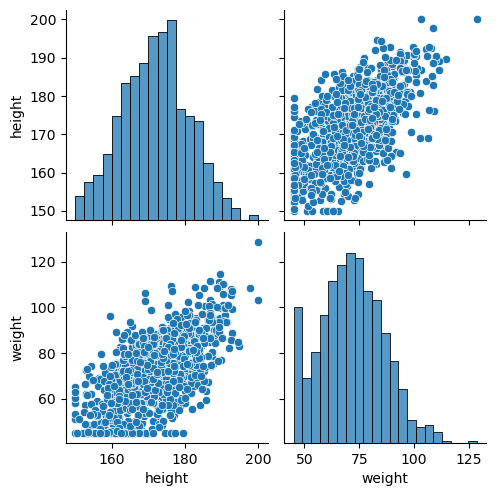

In [17]:
# используем попарное распределение признаков
sns.pairplot(data[eis]);

Очень удобный способ сравнения, работающий по принципу таблицы умножения. Попробуем добавить к этим признакам возрастную группу, окрашенную в другой цвет

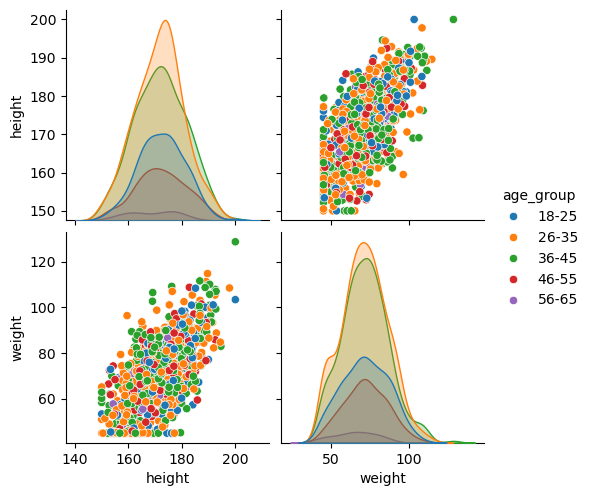

In [18]:
sns.pairplot(data[eis+['age_group']], hue='age_group');

По данным графикам можно заметить, что самые высокие и тяжёлые возрастные группы идут от 26 до 45 лет (отрыв значительный).
Попробуем задать пользовательские заголовки и цвета с помощью matplotlib

Text(0.5, 1.0, 'Распределение по росту и весу')

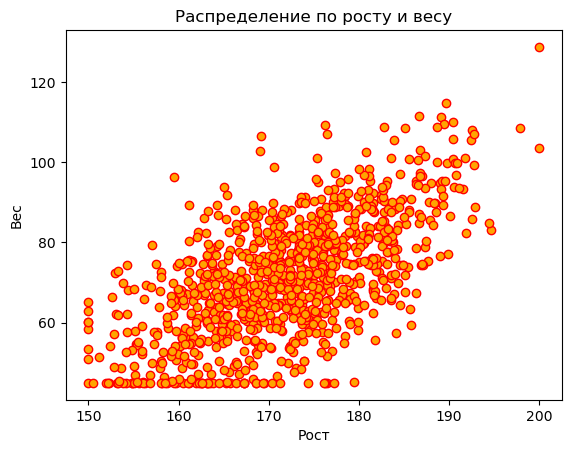

In [19]:
plt.scatter(data['height'], data['weight'], 
            color='orange',edgecolors='red')
plt.xlabel('Рост')
plt.ylabel('Вес')
plt.title('Распределение по росту и весу')

Из интересного, упущеного ранее, но заметного сейчас - на платформе скорее всего стоят минимальные значения роста и веса, из-за чего, как в случае с возрастом, пользователи ниже минимального показателя вынуждены указывать неверные данные о себе (заметно из-за большего горизонтального и вертикального скопления точек у места начала отсчёта). На графиках выше также видно эту особенность.
Попробуем составить чуть более информативный график, где соотнесём рост и вес с конверсией пользователей:

Text(0.5, 1.0, 'Распределение роста и веса с конверсией')

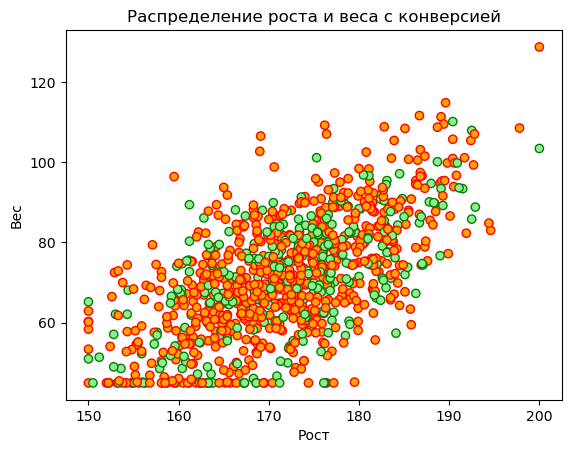

In [20]:
c = data['target'].map({1:'lightgreen', 0:'orange'})
edge_c = data['target'].map({1:'green', 0:'red'})
plt.scatter(data['height'], data['weight'],
            color = c, edgecolors=edge_c)
plt.xlabel('Рост')
plt.ylabel('Вес')
plt.title('Распределение роста и веса с конверсией')

К счастью, как можно видеть по графику, продукт не имеет ограничений по росту и весу и хорошо подходит под любые физические параметры пользователя.

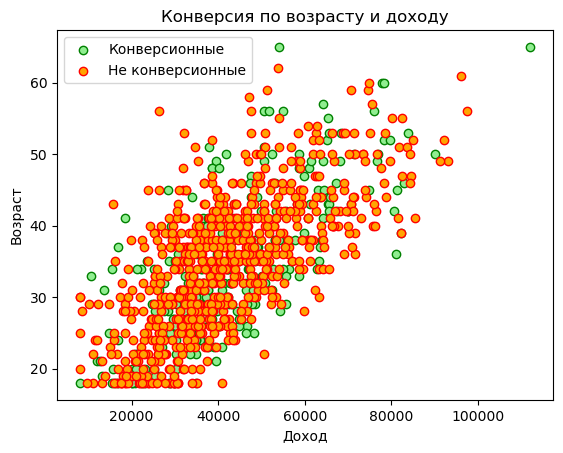

In [21]:
# создадим новый показатель конверсии, представленный в булевом формате
data['targetB'] = data['target'].astype(bool)

# конверсионные пользователи
data_target = data[data['targetB']]
# пользователи с конверсией 0
data_no_target = data[~data['targetB']]

plt.scatter(data_target['income'],data_target['age'],
            color = 'lightgreen', edgecolor='green',
            label='Конверсионные')
plt.scatter(data_no_target['income'],data_no_target['age'],
            color = 'orange', edgecolor='red',
            label='Не конверсионные')
plt.xlabel('Доход')
plt.ylabel('Возраст')
plt.title('Конверсия по возрасту и доходу')
plt.legend();

Как можно судить из результатов диаграммы - конверсия слабо зависит от возраста и дохода (в середине огромное количество оранжевых точек перекрывает зелёные, но это не говорит, что их нет, просто количественно больше и того, и другого). При том подтверждается теория, озвученная выше, о минимальном возрасте (это видно из большого горизонтального скопления точек на минимальном его значении).

## 6. Корреляция признаков

In [22]:
data.corr(numeric_only = True)

,age,income,score,height,weight,visits,clicks,time_spent,target,targetB
age,1.000000,0.691308,-0.103723,-0.013170,-0.029361,-0.458362,-0.377559,-0.298998,-0.001743,-0.001743
income,0.691308,1.000000,-0.045377,-0.039659,-0.041636,-0.304234,-0.236501,-0.197214,0.039634,0.039634
score,-0.103723,-0.045377,1.000000,-0.036278,-0.058123,0.302531,0.668515,0.546675,0.095167,0.095167
height,-0.013170,-0.039659,-0.036278,1.000000,0.626155,-0.002480,-0.027080,-0.028008,0.022350,0.022350
weight,-0.029361,-0.041636,-0.058123,0.626155,1.000000,0.024795,-0.023200,-0.018333,-0.000057,-0.000057
visits,-0.458362,-0.304234,0.302531,-0.002480,0.024795,1.000000,0.850146,0.687937,0.037258,0.037258
clicks,-0.377559,-0.236501,0.668515,-0.027080,-0.023200,0.850146,1.000000,0.816264,0.074669,0.074669
time_spent,-0.298998,-0.197214,0.546675,-0.028008,-0.018333,0.687937,0.816264,1.000000,0.052664,0.052664
target,-0.001743,0.039634,0.095167,0.022350,-0.000057,0.037258,0.074669,0.052664,1.000000,1.000000
targetB,-0.001743,0.039634,0.095167,0.022350,-0.000057,0.037258,0.074669,0.052664,1.000000,1.000000


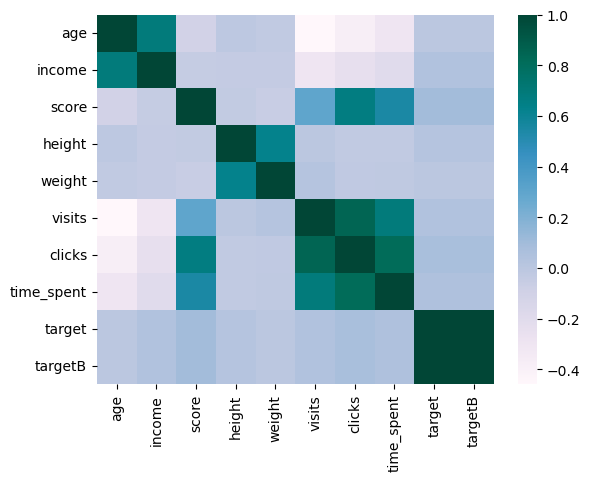

In [23]:
# воспользуемся графиком, выделяющим самую значительную корреляцию
sns.heatmap(data.corr(numeric_only = True), cmap=plt.cm.PuBuGn);

In [24]:
# удалим коррелирующие признаки

data_uncorr=data.drop(['income', 'weight', 'visits', 'time_spent', 'targetB', 'score'], axis=1)
data_uncorr.columns

Index(['age', 'height', 'clicks', 'target', 'age_group'], dtype='object')

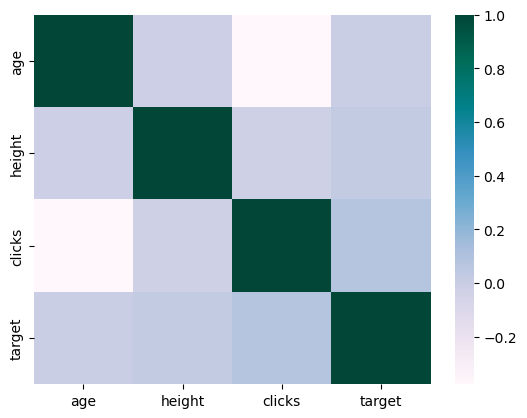

In [25]:
# heatmap без коррелирующих признаков
sns.heatmap(data_uncorr.corr(numeric_only=True), cmap=plt.cm.PuBuGn);

Коррелирующие признаки удалены, отлично! Конец лабораторной работы.